In [1]:
# Notebooks live in Notebooks/, but every data path is relative to the repo root.
import os, sys
while not os.path.isdir("data") and os.getcwd() != "/":
    os.chdir("..")
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())
print("cwd:", os.getcwd())

cwd: /home/lotan.amit/WhatDoLLMsWant


# Deck 5 figures — the three big models

Two figures of `figs4deck5_fix`, redrawn with one panel per model.

| figure | in `figs4deck5_fix` | models here | what it shows |
|---|---|---|---|
| **Fig 6.2** `s06_brand_trajectories` | 2 x 4 grid, one panel per model | qwen-72B, gemma-27B, olmo-32B | Apple's decay: every brand's weight across none → 14in → 8GB → 14in+8GB |
| **Fig 5.5 D** `s05_adherence_D_split` | 2 panels (screen, RAM), models on the x-axis | **qwen-32B**, gemma-27B, olmo-32B | adherence, split into "obeying is free" and "obeying costs" |

The adherence figure here plots **Δp** (a probability gap, defined below) as the bar height, not the win rate.

Synthetic laptops only, frame `shopping`, 9900 rows per run. Notation and the definition of `D`, `A`, `g`, `kappa`:
see the top of `figs4deck5_fix`.

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from matplotlib.legend_handler import HandlerTuple
from src.bt import FeatureBT

FIGDIR = "figs/deck5_big3"
os.makedirs(FIGDIR, exist_ok=True)

FOLDERS = ["data/laptops_robustness", "data/laptops_robustness_gemma", "data/laptops_olmo"]
BRANDS = ["ASUS", "Apple", "Dell", "HP", "Lenovo"]
CON = ["none", "screen=14-inch", "ram=8GB", "ram=8GB+screen=14-inch"]
CLAB = dict(zip(CON, ["none", "14in", "8GB", "14in+8GB"]))
cols = [CLAB[c] for c in CON]
ALL = [("qwen", "72"), ("gemma", "27"), ("olmo", "32")]      # Fig 6.2
ADH = [("qwen", "32"), ("gemma", "27"), ("olmo", "32")]      # Fig 5.5 D
MODELS = list(dict.fromkeys(ALL + ADH))                       # every model loaded, in order
def lbl(f, s): return f"{f}-{s}B"

# same colours, markers and rcParams as figs4deck5_fix
BRAND_COLOR = dict(zip(BRANDS, ["#2a78d6", "#eda100", "#e87ba4", "#008300", "#4a3aa7"]))
BRAND_MARKER = dict(zip(BRANDS, ["o", "s", "^", "D", "v"]))
FEATURE_COLOR = {"brand": "#2a78d6", "screen": "#eb6834", "ram": "#1baf7a"}
SATISFY, VIOLATE = "#2a78d6", "#e34948"
SURFACE, INK, INK_MUTED = "#fcfcfb", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": "#d6d5d1", "axes.labelcolor": INK, "axes.titlecolor": INK,
    "text.color": INK, "xtick.color": INK_MUTED, "ytick.color": INK_MUTED,
    "axes.grid": True, "grid.color": "#e8e7e3", "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110,
    "font.size": 10, "savefig.bbox": "tight", "savefig.dpi": 200,
})


def save(fig, name):
    fig.savefig(os.path.join(FIGDIR, name + ".png"), facecolor=SURFACE)
    fig.savefig(os.path.join(FIGDIR, name + ".pdf"), facecolor=SURFACE)

## Load the runs (4 models x 4 contracts) and fit

In [3]:
RUNS, PATH = {}, {}    # (family, size, constraints_id) -> scores / run path
for folder in FOLDERS:
    for r in sorted(os.listdir(folder)):
        cf, sc = f"{folder}/{r}/config.json", f"{folder}/{r}/scores.csv"
        if not (os.path.isfile(cf) and os.path.isfile(sc)):
            continue                                   # config without scores = a dead run
        c = json.load(open(cf))
        key = (c["model_family"], str(c["model_size"]), c["constraints_id"])
        if key[:2] not in MODELS or c["frame"]["name"] != "shopping" or key[2] not in CON:
            continue
        assert key not in RUNS, f"two runs share the key {key}"
        RUNS[key], PATH[key] = pd.read_csv(sc), f"{folder}/{r}"
        assert len(RUNS[key]) == 9900
assert len(RUNS) == len(MODELS) * len(CON), len(RUNS)

FITS = {k: FeatureBT(r2_warn=None).fit(d) for k, d in RUNS.items()}
print(pd.DataFrame([dict(model=lbl(f, s), contract=c, run=PATH[(f, s, c)], R2=FITS[(f, s, c)].r2_)
                    for f, s in MODELS for c in CON]).round(2).to_string(index=False))

    model               contract                                    run   R2
 qwen-72B                   none        data/laptops_robustness/1271581 0.86
 qwen-72B         screen=14-inch       data/laptops_robustness/68339920 0.85
 qwen-72B                ram=8GB       data/laptops_robustness/68374671 0.92
 qwen-72B ram=8GB+screen=14-inch       data/laptops_robustness/68374672 0.88
gemma-27B                   none data/laptops_robustness_gemma/68378741 0.79
gemma-27B         screen=14-inch data/laptops_robustness_gemma/68378313 0.78
gemma-27B                ram=8GB data/laptops_robustness_gemma/68378314 0.78
gemma-27B ram=8GB+screen=14-inch data/laptops_robustness_gemma/68378315 0.78
 olmo-32B                   none              data/laptops_olmo/1319097 0.91
 olmo-32B         screen=14-inch              data/laptops_olmo/1320479 0.82
 olmo-32B                ram=8GB              data/laptops_olmo/1320480 0.93
 olmo-32B ram=8GB+screen=14-inch              data/laptops_olmo/1320481 0.86

---
# Fig 6.2 — every brand's weight across the four contracts

Each line is one brand's weight $w_{\text{brand}}(\ell)$ across the four contract conditions, fitted on all 9900 rows
of that run. Weights are centred, so 0 is the average brand. **None of the four contracts mentions brand.**
Apple is drawn bold. Each panel has its own y-axis.

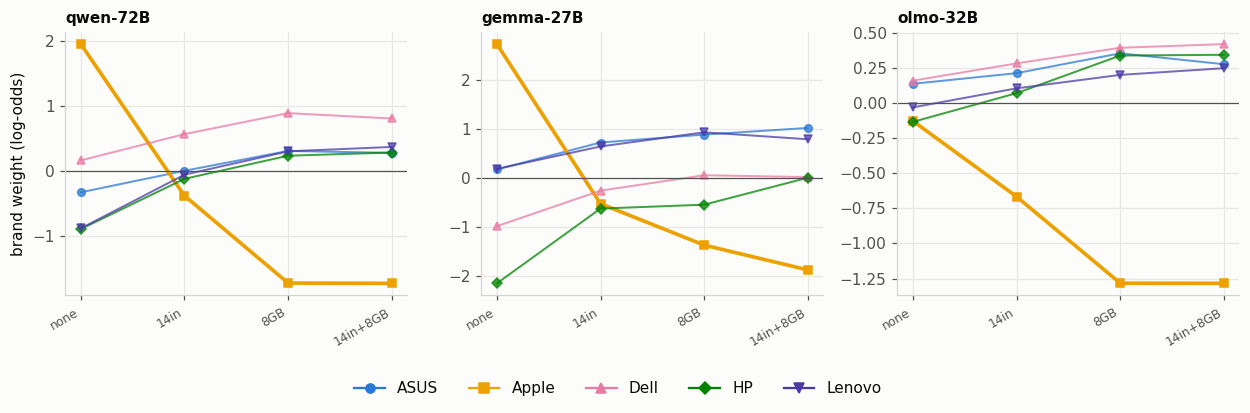

Apple's brand weight per contract (log-odds), how far it travels, and its rank among the 5 brands:
           none  14in   8GB  14in+8GB  swing  rank none  rank 14in  rank 8GB  rank 14in+8GB
model                                                                                      
qwen-72B   1.95 -0.38 -1.73     -1.73   3.68          1          5         5              5
gemma-27B  2.74 -0.52 -1.36     -1.87   4.60          1          4         5              5
olmo-32B  -0.13 -0.67 -1.28     -1.28   1.16          4          5         5              5


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(11.6, 3.7))
for ax, (fam, s) in zip(axes, ALL):
    for b in BRANDS:
        y = [FITS[(fam, s, c)].weights_["brand"][b] for c in CON]
        ax.plot(range(4), y, "-", marker=BRAND_MARKER[b], color=BRAND_COLOR[b],
                ms=5, lw=2.4 if b == "Apple" else 1.3,
                alpha=1.0 if b == "Apple" else .75)
    ax.axhline(0, color=INK_MUTED, lw=.8)
    ax.set_xticks(range(4), cols, rotation=30, ha="right", fontsize=8)
    ax.set_title(lbl(fam, s), loc="left", fontweight="bold", fontsize=10)
axes[0].set_ylabel("brand weight (log-odds)")
fig.legend(handles=[Line2D([], [], marker=BRAND_MARKER[b], color=BRAND_COLOR[b], label=b)
                    for b in BRANDS], ncol=5, loc="lower center", frameon=False,
           bbox_to_anchor=(.5, -.02))
fig.tight_layout(rect=[0, .09, 1, 1])
save(fig, "s06_brand_trajectories")
plt.show()

print("Apple's brand weight per contract (log-odds), how far it travels, and its rank among the 5 brands:")
ap = pd.DataFrame([dict(model=lbl(f, s),
                        **{CLAB[c]: FITS[(f, s, c)].weights_["brand"]["Apple"] for c in CON})
                   for f, s in ALL]).set_index("model")
ap["swing"] = ap.max(axis=1) - ap.min(axis=1)
rank = pd.DataFrame([dict(model=lbl(f, s),
                          **{f"rank {CLAB[c]}": int(pd.Series(FITS[(f, s, c)].weights_["brand"])
                                                    .rank(ascending=False)["Apple"]) for c in CON})
                     for f, s in ALL]).set_index("model")
print(ap.join(rank).round(2).to_string())

---
# Fig 5.5 D — adherence, split into the two directions a contract creates

A contract that says *8GB* creates two comparisons:

| direction | pair | what obeying costs |
|---|---|---|
| **AGREE** | 8GB vs 4GB | nothing — the contract and the model's own taste want the same laptop |
| **CONFLICT** | 8GB vs 16GB | a RAM step — the model must give up something it wants |

Same for `screen=14-inch` (agree: 14 vs 13 inch, conflict: 14 vs 16 inch). **Which pairs:** brand tied, the other
spec feature tied, so the named feature is the only difference — 75 unordered pairs per bar.

**Bar height = Δp**, how strongly the model picks the asked-for laptop over the other one:

- **Δp** = mean of $P(\text{asked-for laptop}) - P(\text{other laptop})$ over the 150 prompts (75 pairs x both slot
  orders). The two answer probabilities are normalised to sum to 1, so per prompt this is $\tanh(m/2)$, with the
  PMI offset $C$ added back to $m$ first (qwen and gemma were collected with PMI on, olmo with it off).
  **+1 = always picks the asked-for laptop, 0 = a coin flip (dashed), −1 = always picks the other one.**
- It is **not position-corrected:** the slot bias is inside it, averaged over the two orders. So it can be below 1
  while the position-corrected win rate (the `conflict` column of the table, from $D$) is 100%.
- The bars are the **conflict pairs only**, under the contract. Δp on the agree pairs (`dp_agree`) and on the same
  conflict pairs with no contract (`dp_before`, near −1: on its own the model picks the bigger screen / RAM) are in
  the table, not in the figure.

**The number above each bar** is its Δp. The table also keeps the win rates, $g_0 \to g_1$ (the mean
position-corrected margin $D$ in log-odds; compare it only inside one model, status point 10) and $\kappa$.

In [5]:
def paired_D(d, mask, a_is_candidate):
    """One D = u(candidate) - u(other) per unordered pair, position-corrected.

    Each unordered pair appears twice, once per slot order:
        candidate in slot A:  +m = u_c - u_o + gamma
        candidate in slot B:  -m = u_c - u_o - gamma
    so the mean of the two is u_c - u_o. Immune to gamma, to the PMI constant C, and to
    any other additive constant. Pairs not seen in both orders are dropped.
    """
    m = (d.score_a - d.score_b).values
    A = (d.a_brand + "|" + d.a_screen + "|" + d.a_ram).values
    B = (d.b_brand + "|" + d.b_screen + "|" + d.b_ram).values
    first, second = np.where(A < B, A, B), np.where(A < B, B, A)
    key = np.char.add(np.char.add(first.astype(str), "##" + second.astype(str)),
                      "##" + d.template_idx.astype(str).values)
    t = pd.DataFrame({"key": key, "v": np.where(a_is_candidate, m, -m)})[np.asarray(mask)]
    g = t.groupby("key")["v"].agg(["mean", "size"])
    return g[g["size"] == 2]["mean"].values


def winrate(d, mask, a_is_candidate):
    """A: % of unordered pairs the candidate wins."""
    D = paired_D(d, mask, a_is_candidate)
    return 100 * float((D > 0).mean()) if len(D) else np.nan


def gap(d, mask, a_is_candidate):
    """g: mean position-corrected margin, in log-odds, on THESE pairs only."""
    D = paired_D(d, mask, a_is_candidate)
    return float(D.mean()) if len(D) else np.nan


def only_one(d, feat):
    """Rows where a and b differ in `feat` and are tied on every other feature."""
    m = (d[f"a_{feat}"] != d[f"b_{feat}"]).values.copy()
    for o in [f for f in ("brand", "screen", "ram") if f != feat]:
        m &= (d[f"a_{o}"] == d[f"b_{o}"]).values
    return m


def pair_of(d, feat, u, v):
    """Rows whose `feat` values are exactly {u, v}, in either order."""
    return (((d[f"a_{feat}"] == u) & (d[f"b_{feat}"] == v))
            | ((d[f"a_{feat}"] == v) & (d[f"b_{feat}"] == u))).values


def pmi_offset(runs, tol=0.01, min_sat=0.01):
    """C = logP(L1|base) - logP(L2|base), recovered from saturation (copied from figs4deck5_fix).
    A saturated prompt has logP(L|prompt) ~ 0, so max(score) ~ -logP(L|base). Returns (C, saturation share).
    About 0 for a run collected with PMI off."""
    mA = max(d.score_a.max() for d in runs)
    mB = max(d.score_b.max() for d in runs)
    sat = min(max((d.score_a > mA - tol).mean() for d in runs),
              max((d.score_b > mB - tol).mean() for d in runs))
    return (mB - mA if sat >= min_sat else np.nan), sat


def prob_gap(d, mask, a_is_candidate, C):
    """Δp: mean over the prompts of P(candidate) - P(other), the two answer probabilities normalised to sum
    to 1, after adding the PMI offset C back. Per prompt, NOT position-corrected."""
    m = (d.score_a - d.score_b).values + C
    return float(np.tanh(np.where(a_is_candidate, m, -m)[mask] / 2).mean())


# C depends only on the model: pool its four runs
PMI_C = {}
for fam, s in MODELS:
    PMI_C[(fam, s)], sat = pmi_offset([RUNS[(fam, s, c)] for c in CON])
    print(f"{lbl(fam, s)}: C = {PMI_C[(fam, s)]:.2f}  (saturation {sat:.2f})")

qwen-72B: C = 5.62  (saturation 0.41)
gemma-27B: C = 5.24  (saturation 0.50)
olmo-32B: C = -0.00  (saturation 0.20)
qwen-32B: C = 2.25  (saturation 0.41)


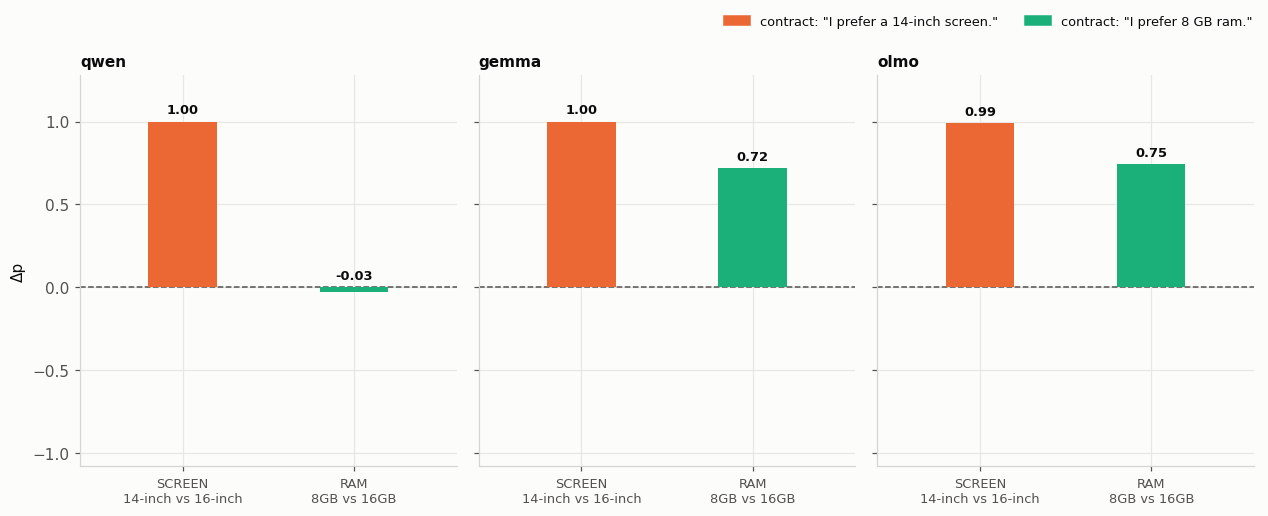

                  n_pairs  before  conflict  agree     g0     g1  kappa  dp_before    dp  dp_agree
model     feat                                                                                    
qwen-32B  screen       75    0.00    100.00  100.0 -10.07  26.02   3.58      -0.66  1.00      1.00
          ram          75    0.00     17.33  100.0 -27.35  -2.56   0.91      -1.00 -0.03      1.00
gemma-27B screen       75    0.00    100.00  100.0 -17.05  22.80   2.34      -1.00  1.00      1.00
          ram          75    0.00    100.00  100.0 -22.70  12.12   1.53      -1.00  0.72      1.00
olmo-32B  screen       75   21.33    100.00  100.0  -0.52   7.76  15.87      -0.21  0.99      0.98
          ram          75    0.00    100.00  100.0  -5.17   4.06   1.79      -0.98  0.75      1.00


In [6]:
ASKED   = {"screen": "14-inch", "ram": "8GB"}
RIVAL   = {"screen": "16-inch", "ram": "16GB"}     # conflict: the model's own favourite
FRIEND  = {"screen": "13-inch", "ram": "4GB"}      # agree: obeying is free
RUN_OF  = {"screen": "screen=14-inch", "ram": "ram=8GB"}
FEATS2  = ["screen", "ram"]

rows = []
for fam, s in ADH:
    for feat in FEATS2:
        d1, d0 = RUNS[(fam, s, RUN_OF[feat])], RUNS[(fam, s, "none")]
        w1 = (d1[f"a_{feat}"] == ASKED[feat]).values     # is slot A the asked-for level?
        w0 = (d0[f"a_{feat}"] == ASKED[feat]).values
        agree_m1 = only_one(d1, feat) & pair_of(d1, feat, ASKED[feat], FRIEND[feat])
        confl_m1 = only_one(d1, feat) & pair_of(d1, feat, ASKED[feat], RIVAL[feat])
        confl_m0 = only_one(d0, feat) & pair_of(d0, feat, ASKED[feat], RIVAL[feat])
        g0, g1 = gap(d0, confl_m0, w0), gap(d1, confl_m1, w1)
        rows.append(dict(
            model=lbl(fam, s), feat=feat, n_pairs=len(paired_D(d1, confl_m1, w1)),
            agree=winrate(d1, agree_m1, w1),
            conflict=winrate(d1, confl_m1, w1),
            before=winrate(d0, confl_m0, w0),
            g0=g0, g1=g1, kappa=1 - g1 / g0,
            dp_agree=prob_gap(d1, agree_m1, w1, PMI_C[(fam, s)]),
            dp=prob_gap(d1, confl_m1, w1, PMI_C[(fam, s)]),
            dp_before=prob_gap(d0, confl_m0, w0, PMI_C[(fam, s)])))
SPLIT = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(11.6, 4.4), sharey=True)
x = np.arange(len(FEATS2))
for ax, (fam, s) in zip(axes, ADH):
    t = SPLIT[SPLIT.model == lbl(fam, s)].set_index("feat").reindex(FEATS2)
    ax.bar(x, t.dp, .40, color=[FEATURE_COLOR[f] for f in FEATS2], zorder=3)
    ax.axhline(0, color=INK_MUTED, ls="--", lw=1)     # coin flip
    for xi, f in zip(x, FEATS2):
        top = max(t.dp[f], 0)
        ax.text(xi, top + .03, f"{t.dp[f]:.2f}", ha="center", va="bottom",
                fontsize=8.5, fontweight="bold", color=INK, zorder=6)
    ax.set_xticks(x, [f"{f.upper()}\n{ASKED[f]} vs {RIVAL[f]}" for f in FEATS2],
                  fontsize=8.5)
    ax.set_xlim(-.6, len(FEATS2) - .4)
    ax.set_ylim(-1.08, 1.28)
    ax.set_yticks([-1, -.5, 0, .5, 1])
    ax.set_title(fam, loc="left", fontweight="bold", fontsize=10)
axes[0].set_ylabel("Δp")
# the legend names the contract behind each colour, with the text exactly as it was in the prompt
TEXT = {}
for f in FEATS2:
    texts = {json.load(open(f"{PATH[(fam, s, RUN_OF[f])]}/config.json"))["constraints_text"] for fam, s in ADH}
    assert len(texts) == 1, texts                     # the same contract sentence in all three models
    TEXT[f] = texts.pop()
fig.legend(handles=[Rectangle((0, 0), 1, 1, color=FEATURE_COLOR[f]) for f in FEATS2],
           labels=[f'contract: "{TEXT[f]}"' for f in FEATS2],
           loc="upper right", ncol=2, frameon=False, fontsize=8.5,
           bbox_to_anchor=(.995, 1.07))
fig.tight_layout()
save(fig, "s05_adherence_D_split")
plt.show()

out = SPLIT.set_index(["model", "feat"])[["n_pairs", "before", "conflict", "agree", "g0", "g1", "kappa",
                                          "dp_before", "dp", "dp_agree"]]
print(out.round(2).to_string())